# 02 — Exploration (Spark SQL) et séparation temporelle

Scénario : le modèle note **chaque transaction au moment où elle est demandée**, avant sa validation,
pour la signaler à un analyste. On garde donc les **5 types** de transaction et on laisse `type` au modèle.

Entrée : `data/propre/transactions.parquet`.
Sortie : `data/ml/train.parquet`, `data/ml/validation.parquet`, `data/ml/test.parquet`, séparés par `step`.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("fraude-02-exploration")
         .master("spark://spark-master:7077")
         .config("spark.driver.host", "spark-master")
         .config("spark.driver.memory", "2g")
         .config("spark.executor.memory", "2g")
         .config("spark.sql.shuffle.partitions", "18")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.eventLog.enabled", "true")
         .config("spark.eventLog.dir", "file:///tmp/spark-events")
         .getOrCreate())

DATA = "/opt/spark-data"
spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/24 14:56:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
df = spark.read.parquet(DATA + "/propre/transactions.parquet")
df.createOrReplaceTempView("transactions")
print("Lignes :", df.count())

[Stage 1:===================>                                       (3 + 6) / 9]

Lignes : 6292904


## Déséquilibre des classes

In [3]:
spark.sql("""
    SELECT label, COUNT(*) AS nb
    FROM transactions
    GROUP BY label
""").show()

[Stage 4:=======================================>                   (6 + 3) / 9]

+-----+-------+
|label|     nb|
+-----+-------+
|  0.0|6284787|
|  1.0|   8117|
+-----+-------+



8 117 fraudes sur 6 292 904 transactions, soit 0,13 %. Un modèle qui répond toujours « normal » aurait 99,87 % d'accuracy : on utilisera donc la PR-AUC, la précision et le rappel sur la classe fraude.

## Fraudes par type de transaction

In [4]:
spark.sql("""
    SELECT type,
           COUNT(*)                   AS nb,
           SUM(label)                 AS nb_fraudes,
           ROUND(100 * AVG(label), 3) AS taux_fraude_pct
    FROM transactions
    GROUP BY type
    ORDER BY nb_fraudes DESC
""").show()

[Stage 7:======>                                                    (1 + 8) / 9]

+--------+-------+----------+---------------+
|    type|     nb|nb_fraudes|taux_fraude_pct|
+--------+-------+----------+---------------+
|CASH_OUT|2213096|    4068.0|          0.184|
|TRANSFER| 527206|    4049.0|          0.768|
|   DEBIT|  40976|       0.0|            0.0|
| CASH_IN|1383815|       0.0|            0.0|
| PAYMENT|2127811|       0.0|            0.0|
+--------+-------+----------+---------------+



Les fraudes n'existent que dans `CASH_OUT` et `TRANSFER`.

**Pourquoi garder les 5 types** : le modèle doit noter toutes les transactions qui arrivent. Il apprend lui-même, grâce à la variable `type`, que les autres types ne sont pas frauduleux.

## Montants

In [5]:
spark.sql("""
    SELECT label,
           ROUND(MIN(amount), 2)                    AS min,
           ROUND(percentile_approx(amount, 0.5), 2) AS mediane,
           ROUND(AVG(amount), 2)                    AS moyenne,
           ROUND(MAX(amount), 2)                    AS max
    FROM transactions
    GROUP BY label
""").show()

[Stage 10:===================>                                      (3 + 6) / 9]

+-----+----+---------+----------+-------------+
|label| min|  mediane|   moyenne|          max|
+-----+----+---------+----------+-------------+
|  0.0|0.01| 74684.47| 178156.49|9.244551664E7|
|  1.0| 0.0|440962.56|1468601.16|        1.0E7|
+-----+----+---------+----------+-------------+



Les fraudes portent sur des montants plus élevés (médiane 440 963 contre 74 685). Le maximum des fraudes est exactement 10 000 000, ce qui ressemble à un plafond du simulateur.

## Taux de fraude par heure de la journée
Heure tirée de `step` : `(step - 1) % 24`.

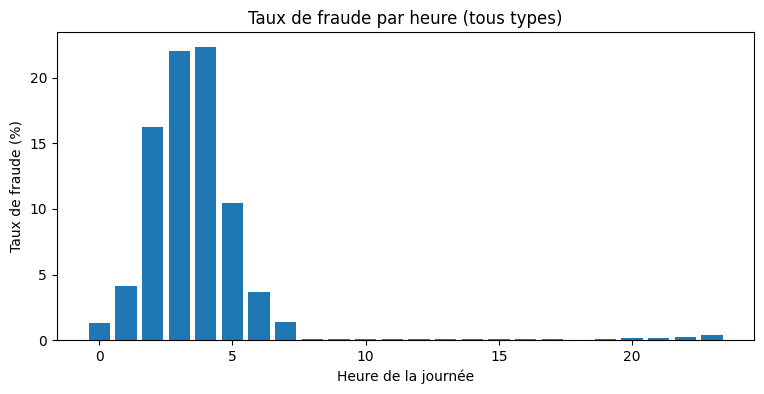

In [6]:
import matplotlib.pyplot as plt

par_heure = spark.sql("""
    SELECT (step - 1) % 24 AS heure, 100 * AVG(label) AS taux_fraude_pct
    FROM transactions
    GROUP BY (step - 1) % 24
    ORDER BY heure
""").toPandas()

plt.figure(figsize=(9, 4))
plt.bar(par_heure["heure"], par_heure["taux_fraude_pct"])
plt.xlabel("Heure de la journée")      # axe X
plt.ylabel("Taux de fraude (%)")       # axe Y
plt.title("Taux de fraude par heure (tous types)")
plt.show()

Axe X : heure de la journée ; axe Y : taux de fraude.

Les fraudes se concentrent la nuit : environ 22 % des transactions vers 3 h – 4 h sont des fraudes, contre presque 0 % en journée. Les fraudeurs agissent à toute heure, alors que les clients normaux sont surtout actifs le jour. L'heure est donc une variable utile.

## Volume et fraudes au fil du temps

Avant de couper par `step`, on regarde comment les transactions et les fraudes se répartissent dans le temps.

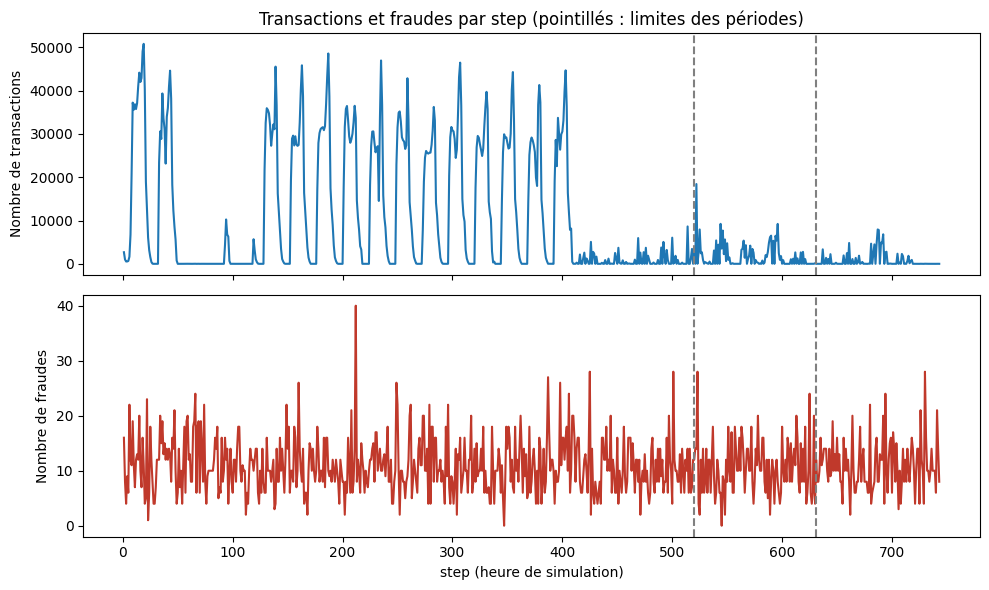

In [7]:
par_step = spark.sql("""
    SELECT step, COUNT(*) AS nb, SUM(label) AS nb_fraudes
    FROM transactions
    GROUP BY step
    ORDER BY step
""").toPandas()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(par_step["step"], par_step["nb"])
axes[0].set_ylabel("Nombre de transactions")        # axe Y (haut)
axes[1].plot(par_step["step"], par_step["nb_fraudes"], color="#c0392b")
axes[1].set_ylabel("Nombre de fraudes")             # axe Y (bas)
axes[1].set_xlabel("step (heure de simulation)")     # axe X (commun)
for limite in [520, 631]:
    axes[0].axvline(limite, ls="--", c="grey")
    axes[1].axvline(limite, ls="--", c="grey")
axes[0].set_title("Transactions et fraudes par step (pointillés : limites des périodes)")
plt.tight_layout()
plt.show()

Axe X : step (heure de simulation) ; axe Y : nombre de transactions (en haut), nombre de fraudes (en bas).

- Les transactions normales arrivent par vagues chaque jour, puis **chutent fortement après le step 400 environ**.
- Les fraudes restent régulières (environ 10 par step) jusqu'à la fin.

Conséquence : la proportion de fraudes est beaucoup plus forte en fin de simulation. La validation et le test auront donc plus de fraudes en proportion que l'entraînement.

## Artefacts des soldes de l'émetteur

Dans PaySim, le compte du fraudeur est presque toujours vidé exactement. Ce tableau le mesure :
c'est pour ça que les soldes de l'émetteur sont exclus du modèle principal (notebook 03).

In [8]:
spark.sql("""
    SELECT label,
           ROUND(100 * AVG(CASE WHEN amount = oldbalanceOrg THEN 1 ELSE 0 END), 1) AS pct_montant_egal_solde_emetteur,
           ROUND(100 * AVG(CASE WHEN oldbalanceDest = 0 THEN 1 ELSE 0 END), 1)     AS pct_solde_dest_avant_nul
    FROM transactions
    WHERE type IN ('TRANSFER', 'CASH_OUT')
    GROUP BY label
""").show()

+-----+-------------------------------+------------------------+
|label|pct_montant_egal_solde_emetteur|pct_solde_dest_avant_nul|
+-----+-------------------------------+------------------------+
|  0.0|                            0.0|                    13.6|
|  1.0|                           92.5|                    63.7|
+-----+-------------------------------+------------------------+



- 92,5 % des fraudes ont un montant égal au solde de l'émetteur, contre 0 % des transactions normales. C'est une règle du simulateur (le compte est vidé exactement) : `oldbalanceOrg` est exclu du modèle principal.
- 63,7 % des fraudes ont un solde destinataire à 0 avant la transaction, contre 13,6 % des normales. L'écart est net mais ce n'est pas une règle parfaite. `oldbalanceDest` est connu avant la transaction : on le garde.

## Séparation temporelle : entraînement / validation / test

On veut savoir si le modèle détecte des fraudes **futures**. On coupe donc selon `step`, sans mélanger :

| Période | Steps | Rôle |
|---|---|---|
| Entraînement | 1 – 520 | apprendre le pipeline |
| Validation | 521 – 631 | choisir le modèle, le poids, les hyperparamètres et le seuil |
| Test | 632 – 743 | évaluation finale, utilisée une seule fois (notebook 04) |

In [9]:
train = df.filter(F.col("step") <= 520)
validation = df.filter((F.col("step") > 520) & (F.col("step") <= 631))
test = df.filter(F.col("step") > 631)

train.write.mode("overwrite").parquet(DATA + "/ml/train.parquet")
validation.write.mode("overwrite").parquet(DATA + "/ml/validation.parquet")
test.write.mode("overwrite").parquet(DATA + "/ml/test.parquet")

for nom in ["train", "validation", "test"]:
    partie = spark.read.parquet(DATA + "/ml/" + nom + ".parquet")
    nb = partie.count()
    nb_fraudes = partie.filter("label = 1").count()
    print(f"{nom:<11} : {nb:>9} lignes | {nb_fraudes:>5} fraudes | taux {100 * nb_fraudes / nb:.3f} %")

train       :   6015446 lignes |  5714 fraudes | taux 0.095 %
validation  :    189018 lignes |  1168 fraudes | taux 0.618 %
test        :     88440 lignes |  1235 fraudes | taux 1.396 %


Le taux de fraude passe de 0,095 % (entraînement) à 0,618 % (validation) puis 1,396 % (test), à cause de la chute des transactions normales vue plus haut.

Conséquence : les PR-AUC des différentes périodes ne se comparent pas directement. On compare chaque PR-AUC au **hasard**, qui vaut le taux de fraude de la période.

In [10]:
spark.stop()